# Step 1: Data loading, cloud masking and first EDA

**Goal of this notebook:** turn the raw parquet files into a clean table with ONE trustworthy
reflectance value per (pixel, year), and produce the Day 1 EDA facts the team needs.

**Output:** `clean_madrid.parquet` and `clean_amsterdam.parquet` in `OUT_DIR`. Feature engineering
(Fenny) and modelling (Silvio, Antonio) start from these files, so everyone uses the same clean data.

Needs `data_prep.py` in the same folder.

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import data_prep as dp       # our loading + masking functions (read data_prep.py, it is commented)

DATA_DIR = Path("data")                      # EDIT: where the parquet files are on the VM
FILES = {"Madrid": DATA_DIR / "madrid_train.parquet",
         "Amsterdam": DATA_DIR / "amsterdam_data.parquet"}
EVENTS = {"Madrid": 1960, "Amsterdam": 1945}    # EDIT if the organisers' boundaries differ
OUT_DIR = Path("./clean"); OUT_DIR.mkdir(exist_ok=True)
COMBINE = "median"                              # "median" (ours) or "first" (the notebooks' default)

## 1. Load
`load_city` reads the file and stores the bands as float32, which halves memory use.
`quick_look` prints rows, pixels, years, memory and coverage, so we can check the files are complete.

In [2]:
raw = {}
for city, path in FILES.items():
    t = time.time()
    raw[city] = dp.load_city(path)
    print(f"--- {city} (loaded in {time.time()-t:.1f}s)")
    dp.quick_look(raw[city])
    print()
print("Columns:", list(raw["Madrid"].columns))

--- Madrid (loaded in 0.5s)
City: ['Madrid']
Rows (pixel-years): 3,172,765   Unique pixels: 76,263
Years: 1984 to 2025 (42 distinct)
Memory: 1.26 GB
Coverage: min 0.15, median 0.46
weighted_mean_year: 1850 to 2021

--- Amsterdam (loaded in 0.2s)
City: ['Amsterdam']
Rows (pixel-years): 1,062,877   Unique pixels: 25,992
Years: 1984 to 2025 (42 distinct)
Memory: 0.43 GB
Coverage: min 0.15, median 0.37
weighted_mean_year: 1850 to 2016

Columns: ['pixel_id', 'city', 'year', 'px_key', 'py_key', 'pixel_x', 'pixel_y', 'row', 'col', 'coverage', 'usable_label', 'weighted_mean_year', 'Blue_1', 'Green_1', 'Red_1', 'NIR_1', 'SWIR1_1', 'SWIR2_1', 'QA_PIXEL_1', 'QA_RADSAT_1', 'doy_1', 'scene_id_1', 'dataset_1', 'qa_valid_1', 'Blue_2', 'Green_2', 'Red_2', 'NIR_2', 'SWIR1_2', 'SWIR2_2', 'QA_PIXEL_2', 'QA_RADSAT_2', 'doy_2', 'scene_id_2', 'dataset_2', 'qa_valid_2', 'Blue_3', 'Green_3', 'Red_3', 'NIR_3', 'SWIR1_3', 'SWIR2_3', 'QA_PIXEL_3', 'QA_RADSAT_3', 'doy_3', 'scene_id_3', 'dataset_3', 'qa_valid_3']


## 2. What does each cloud rule remove?

Every row holds up to 3 photos of the same pixel in the same summer (obs 1, 2, 3).
A photo is kept only if it passes ALL of these rules:

| Rule | Why |
|---|---|
| `qa_valid` | The organisers' own clean flag |
| `not_fill` | QA_PIXEL bit 0: no data (e.g. Landsat 7 stripes after its 2003 scan-line failure) |
| `not_cloud`, `not_shadow`, `not_snow` | QA_PIXEL bits 3, 4, 5 |
| `not_dilated` | bit 1: cloud edges, often hazy |
| `not_cirrus` | bit 2: thin high cloud (Landsat 8/9 only). **qa_valid does not check this one** |
| `cloud_conf` | bits 8 and 9: medium or high cloud confidence is rejected |
| `not_saturated` | QA_RADSAT is not 0, meaning a band hit the sensor's maximum |
| `in_range` | Values outside the valid USGS range 7273 to 43636 are errors |
| `not_haze` | Blue > 15,000 is haze the flags missed (found in Notebook 2) |

The table shows how many photos fail each rule. A photo can fail several rules at once.
This table goes straight into the EDA slide.

In [3]:
for city in FILES:
    print(f"=== {city}")
    display(dp.mask_report(raw[city]))

=== Madrid


,present,fails_qa_valid,fails_not_fill,fails_not_cloud,fails_not_shadow,fails_not_snow,fails_not_cirrus,fails_not_dilated,fails_cloud_conf,fails_not_saturated,fails_in_range,fails_not_haze,kept,kept_%
obs_1,3172765.0,157280.0,58791.0,21009.0,39125.0,653.0,2.0,30318.0,49110.0,5545.0,62834.0,1397.0,2985429.0,94.1
obs_2,3172765.0,137000.0,51417.0,19843.0,35628.0,98.0,1.0,28463.0,39046.0,4155.0,54884.0,1126.0,3014101.0,95.0
obs_3,3172765.0,315514.0,27749.0,50151.0,90664.0,74318.0,0.0,75727.0,99445.0,5376.0,33148.0,51736.0,2817167.0,88.8


=== Amsterdam


,present,fails_qa_valid,fails_not_fill,fails_not_cloud,fails_not_shadow,fails_not_snow,fails_not_cirrus,fails_not_dilated,fails_cloud_conf,fails_not_saturated,fails_in_range,fails_not_haze,kept,kept_%
obs_1,1062877.0,344901.0,207169.0,31232.0,30820.0,17772.0,32.0,30745.0,56990.0,16439.0,224311.0,24086.0,697156.0,65.6
obs_2,1062877.0,257612.0,195713.0,27519.0,17219.0,1800.0,0.0,13119.0,41405.0,1109.0,196731.0,690.0,794813.0,74.8
obs_3,1062877.0,270767.0,152721.0,22887.0,15324.0,50556.0,1.0,16332.0,38946.0,9114.0,166700.0,25119.0,781710.0,73.5


## 3. Build the clean table (one value per pixel-year)

**Our improvement: `median` instead of `first`.** The notebooks take the first clean photo of the year.
If that photo has haze the flags missed, it goes straight into the features. The median of 2 or 3
clean photos outvotes one bad photo (with only 2 photos, the median is their average).
`n_clean_obs` records how many photos backed each value, so we know how reliable it is.

In [4]:
clean = {}
for city in FILES:
    c = dp.clean_long_table(raw[city], combine=COMBINE)
    c = dp.add_age_class(c, EVENTS[city])
    clean[city] = c
    kept = len(c) / len(raw[city]) * 100
    print(f"{city}: {len(c):,} clean pixel-years ({kept:.1f}% of rows), "
          f"{c.groupby(['px_key','py_key']).ngroups:,} pixels")
    print("   clean photos per pixel-year:", c["n_clean_obs"].value_counts().sort_index().to_dict())

temporal haze filter removed 32,848 photos (0.37% of clean photos)
Madrid: 3,161,994 clean pixel-years (99.7% of rows), 76,263 pixels
   clean photos per pixel-year: {1: 99494, 2: 503145, 3: 2559355}
temporal haze filter removed 15,513 photos (0.68% of clean photos)
Amsterdam: 1,053,575 clean pixel-years (99.1% of rows), 25,992 pixels
   clean photos per pixel-year: {1: 217231, 2: 468097, 3: 368247}


## 4. Did masking work? Yearly mean Blue, before vs after
Haze makes Blue jump. Notebook 2 showed a spike in 2003. After cleaning, that spike should be gone.

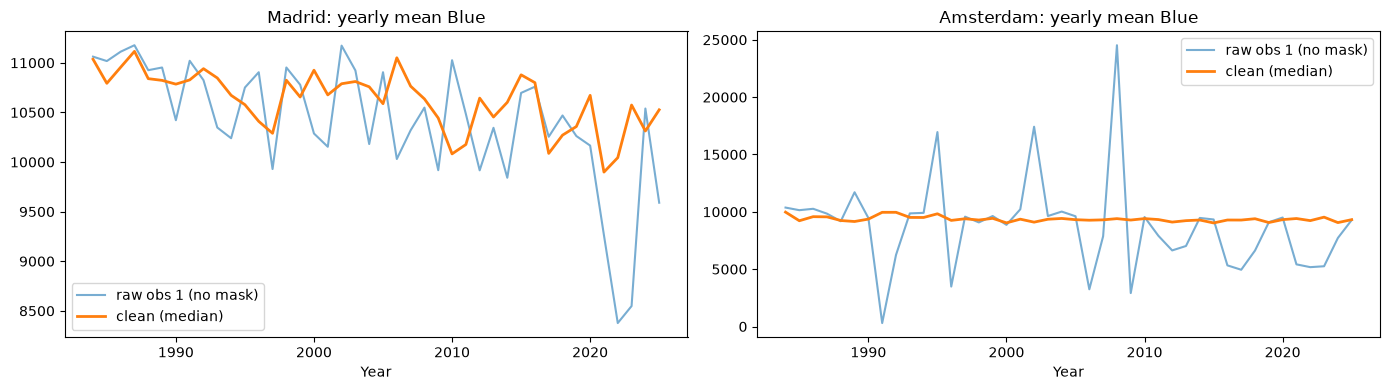

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, city in zip(axes, FILES):
    before = raw[city].groupby("year")["Blue_1"].mean()
    after = clean[city].groupby("year")["Blue"].mean()
    ax.plot(before.index, before.values, label="raw obs 1 (no mask)", alpha=0.6)
    ax.plot(after.index, after.values, label=f"clean ({COMBINE})", linewidth=2)
    ax.set_title(f"{city}: yearly mean Blue"); ax.set_xlabel("Year"); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "mask_check_blue.png", dpi=130); plt.show()

## 5. Which satellite took each year? (sensor changes can look like "age" changes)
Landsat 5 runs to 2013, Landsat 7 from 1999, Landsat 8 from 2013, Landsat 9 from 2021. The bands
were harmonised, but a jump exactly at a sensor change is a warning sign for features.

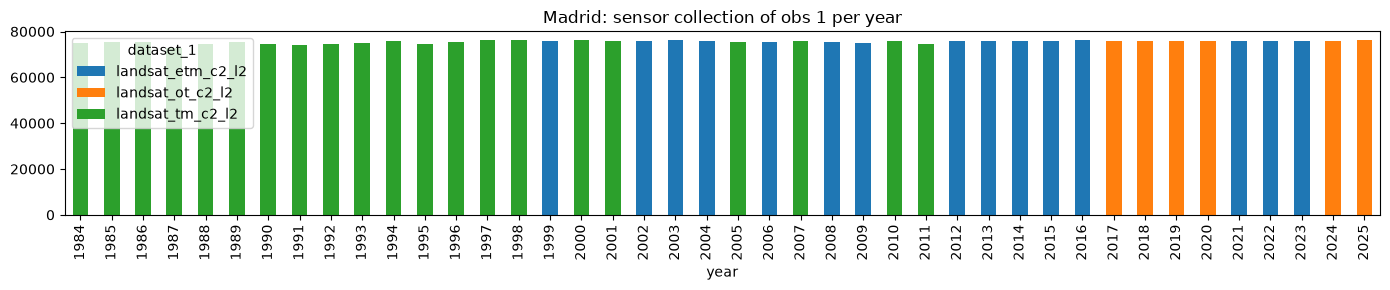

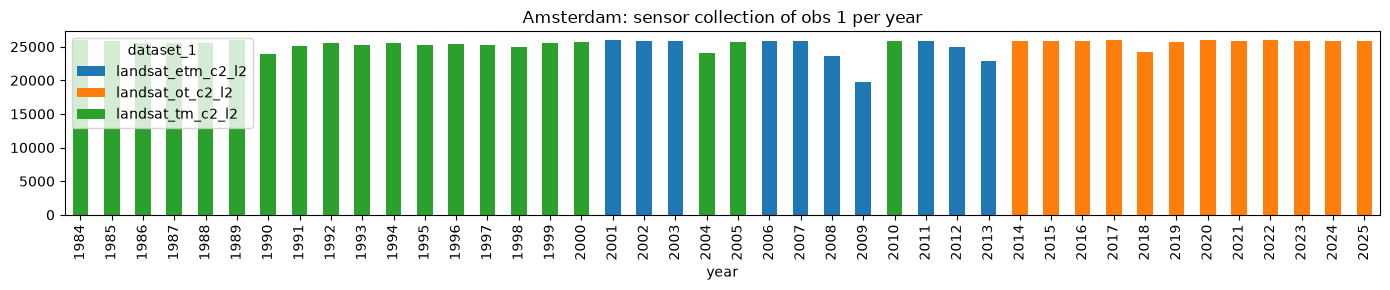

In [6]:
if "dataset_1" in raw["Madrid"].columns:
    for city in FILES:
        tab = pd.crosstab(raw[city]["year"], raw[city]["dataset_1"])
        tab.plot(kind="bar", stacked=True, figsize=(14, 3), title=f"{city}: sensor collection of obs 1 per year")
        plt.tight_layout(); plt.show()

## 6. EDA facts for Day 1 (your job: share these with the team early)
Class counts per city, and how the construction years spread inside each class.

pixels            share_%       
city  Amsterdam   Madrid Amsterdam Madrid
class                                    
1        7568.0  13794.0      29.1   18.1
2        8802.0  27152.0      33.9   35.6
3        6745.0  18672.0      26.0   24.5
4        2877.0  16645.0      11.1   21.8

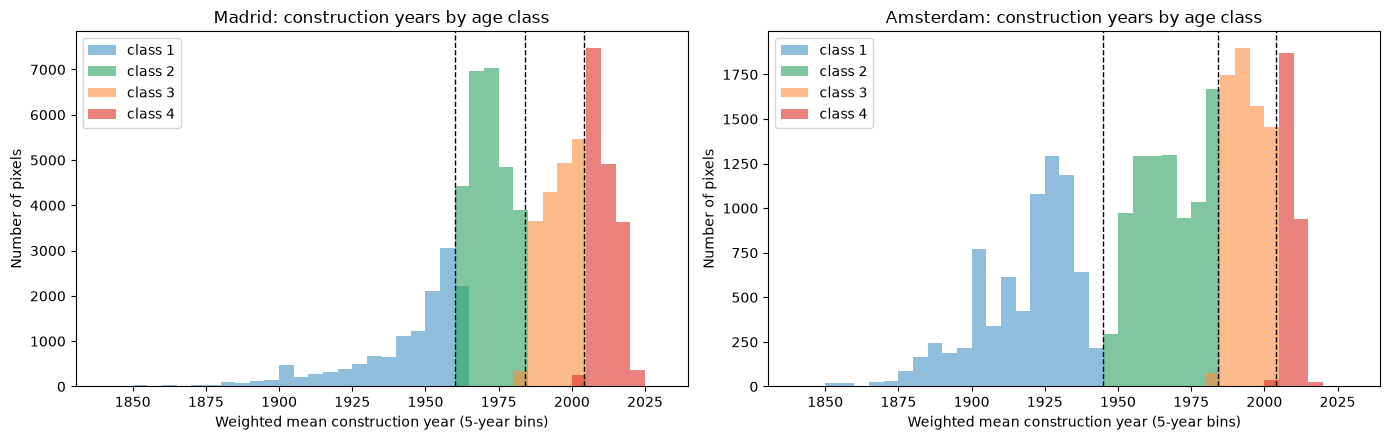

In [7]:
rows = []
for city in FILES:
    pix = clean[city].drop_duplicates(["px_key", "py_key"])
    counts = pix["age_class"].value_counts().sort_index()
    for cls, n in counts.items():
        rows.append({"city": city, "class": cls, "pixels": n, "share_%": round(100 * n / len(pix), 1)})
eda = pd.DataFrame(rows).pivot(index="class", columns="city", values=["pixels", "share_%"])
display(eda)
eda.to_csv(OUT_DIR / "class_counts.csv")
# Histogram of construction years per class, one panel per city
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, city in zip(axes, FILES):
    pix = clean[city].drop_duplicates(["px_key", "py_key"])          # one row per pixel
    for cls, col in zip([1, 2, 3, 4], ["#4393c3", "#2ca25f", "#fd8d3c", "#de2d26"]):
        ax.hist(pix.loc[pix.age_class == cls, "weighted_mean_year"],
                bins=np.arange(1840, 2031, 5),                       # 5-year bins
                alpha=0.6, color=col, label=f"class {cls}")
    for yr in [EVENTS[city], 1984, 2004]:
        ax.axvline(yr, color="k", ls="--", lw=1)
    ax.set_title(f"{city}: construction years by age class")
    ax.set_xlabel("Weighted mean construction year (5-year bins)")   # x axis label
    ax.set_ylabel("Number of pixels")                                # y axis label
    ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "year_distributions.png", dpi=130); plt.show()

### Red flags to check (from the role sheet: anything that would invalidate a model)
* **Empty or tiny classes:** any class with very few pixels in either city?
* **Boundary splitting an era:** a big spike of years sitting right on a class boundary
  (e.g. many buildings at exactly 1960 or 1984) means small date errors flip the class.
* **Label leak:** `weighted_mean_year` must never be used as a feature (it IS the label).
  Also check whether `coverage` differs strongly between classes. If it does, the model may learn
  "density" instead of age, and that may not transfer to a third city.

In [8]:
for city in FILES:
    pix = clean[city].drop_duplicates(["px_key", "py_key"])
    on_boundary = pix["weighted_mean_year"].round().isin([EVENTS[city], 1984, 2004]).mean() * 100
    print(f"{city}: {on_boundary:.1f}% of pixels sit exactly on a class boundary year")
    print("   mean coverage by class:", raw[city].drop_duplicates(["px_key", "py_key"])
          .assign(age_class=lambda d: pd.cut(d.weighted_mean_year, [-np.inf, EVENTS[city], 1984, 2004, np.inf],
                                             labels=[1, 2, 3, 4]))
          .groupby("age_class", observed=True)["coverage"].mean().round(3).to_dict())

Madrid: 6.5% of pixels sit exactly on a class boundary year
   mean coverage by class: {1: 0.5479999780654907, 2: 0.5149999856948853, 3: 0.4580000042915344, 4: 0.5059999823570251}
Amsterdam: 2.9% of pixels sit exactly on a class boundary year
   mean coverage by class: {1: 0.4020000100135803, 2: 0.4000000059604645, 3: 0.44699999690055847, 4: 0.4779999852180481}


## 7. Save the clean tables for the rest of the team

In [9]:
for city in FILES:
    path = OUT_DIR / f"clean_{city.lower()}.parquet"
    clean[city].to_parquet(path, index=False)
    print("saved", path, f"({path.stat().st_size/1e6:.1f} MB)")

saved clean/clean_madrid.parquet (73.4 MB)
saved clean/clean_amsterdam.parquet (24.9 MB)


In [10]:
# ---- Check 1: what is usable_label? ----
for city in FILES:
    print(city, raw[city]["usable_label"].value_counts(dropna=False).to_dict())

# ---- Check 2: does in_range drop values that are too LOW or too HIGH, and in which band? ----
for city in FILES:
    df = raw[city]
    print(f"\n{city}: share of photo-1 values outside 7273..43636, per band")
    for b in dp.BANDS:
        v = df[f"{b}_1"]
        print(f"  {b:6s} too low: {(v < dp.SR_VALID_MIN).mean()*100:5.2f}%   "
              f"too high: {(v > dp.SR_VALID_MAX).mean()*100:5.2f}%")

# ---- Check 3: does the mask remove more photos from some age classes? (bias check) ----
for city in FILES:
    df = dp.add_age_class(raw[city], EVENTS[city])
    rules = dp.slot_mask(df, 1)                       # rules for photo 1
    for rule in ["in_range", "not_snow", "not_haze"]:
        failed = rules["present"] & ~rules[rule]      # photos this rule removed
        rate = failed.groupby(df["age_class"]).mean() * 100
        print(f"{city} | {rule:9s} removed % by class:", rate.round(2).to_dict())

Madrid {True: 3172765}
Amsterdam {True: 1062877}

Madrid: share of photo-1 values outside 7273..43636, per band
  Blue   too low:  1.87%   too high:  0.04%
  Green  too low:  1.85%   too high:  0.02%
  Red    too low:  1.85%   too high:  0.04%
  NIR    too low:  1.85%   too high:  0.00%
  SWIR1  too low:  1.85%   too high:  0.06%
  SWIR2  too low:  1.85%   too high:  0.01%

Amsterdam: share of photo-1 values outside 7273..43636, per band
  Blue   too low: 19.52%   too high:  1.51%
  Green  too low: 19.50%   too high:  1.31%
  Red    too low: 19.50%   too high:  1.36%
  NIR    too low: 19.49%   too high:  0.74%
  SWIR1  too low: 19.50%   too high:  0.18%
  SWIR2  too low: 19.55%   too high:  0.04%
Madrid | in_range  removed % by class: {1: 1.69, 2: 1.84, 3: 2.04, 4: 2.39}
Madrid | not_snow  removed % by class: {1: 0.01, 2: 0.02, 3: 0.02, 4: 0.02}
Madrid | not_haze  removed % by class: {1: 0.0, 2: 0.01, 3: 0.05, 4: 0.13}
Amsterdam | in_range  removed % by class: {1: 19.8, 2: 21.28, 3: 21